<a href="https://colab.research.google.com/github/ilyak0n/image_processing/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%965_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D0%B4%D0%B8%D0%BD%D0%B0%D0%BC%D0%B8%D0%BA%D0%B8_%D0%B8%D0%B7%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B9_%D0%B7%D0%B5%D0%BC%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BF%D0%BE%D0%BA%D1%80%D0%BE%D0%B2%D0%B0_%D0%BD%D0%B0_%D0%BF%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D1%80%D0%B0%D0%B7%D0%BD%D0%BE%D0%B2%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D1%85_%D1%81%D0%BF%D1%83%D1%82%D0%BD%D0%B8%D0%BA%D0%BE%D0%B2%D1%8B%D1%85_%D1%81%D0%BD%D0%B8%D0%BC%D0%BA%D0%BE%D0%B2_%D1%81_%D0%B8%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%D0%BC_%D1%81%D0%BF%D0%B5%D0%BA%D1%82%D1%80%D0%B0%D0%BB%D1%8C%D0%BD%D1%8B%D1%85_%D0%B8%D0%BD%D0%B4%D0%B5%D0%BA%D1%81%D0%BE%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Проектная работа №4. Анализ динамики изменений земного покрова на последовательности разновременных спутниковых снимков с использованием спектральных индексов**

## **1. Цель работы**

Выполнить количественный анализ динамики изменения классов земного покрова на выбранной территории за период с 2019 по 2024 год на основе разновременных спутниковых снимков Sentinel-2 и провести сравнительную оценку результатов, полученных методом пороговой сегментации на основе спектральных индексов и с использованием готовых карт классификации Dynamic World.

## **2. Задачи работы**

1.  **Подготовить** последовательность разновременных снимков (снимки Sentinel-2 и карты Dynamic World) за 2019-2024 гг.;
2.  **Классифицировать** земной покров на снимках Sentinel-2, применив метод пороговой сегментации по спектральным индексам;
3.  **Рассчитать и сравнить** количественные показатели динамики (площади, темпы роста) для двух методов классификации: по индексам и по данным Dynamic World;
4.  **Оценить** выявленные тренды изменения покрова и **сформулировать** выводы о сопоставимости результатов двух методов анализа.

## **3. Загрузка данных для анализа из Google Earth Engine**

> **Примечание.** В качестве примера реализации можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/nWdJIg. Для выполнения текущей работы актуальны только **Раздел 1** и **Раздел 2** указанного источника.





### **3.1. Настройка рабочей среды и аутентификация**

In [5]:
import ee
import geemap
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

ee.Authenticate()
ee.Initialize(project='prac5py')

### **3.2. Определение области интереса**

- Выберите территорию размером не менее 10×10 км (100 км²) с разнообразным земным покровом
- Обязательно должны присутствовать: водные объекты, растительность, застройка, открытая почва
- Зафиксируйте координаты углов ROI для воспроизводимости результатов

In [98]:
roi = ee.Geometry.Rectangle([49.10, 55.70, 49.30, 55.80])

map_roi = geemap.Map(zoom=11)
map_roi.add_basemap('Esri.WorldTopoMap')
map_roi.centerObject(roi, 12)
map_roi.addLayer(roi, {'color': 'red'}, 'Область интереса')
map_roi

Map(center=[55.75001923575946, 49.19999999999812], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.3. Функции для загрузки и обработки данных Sentinel-2**

In [99]:
def load_sentinel2_collection(roi, start_date, end_date, cloud_percentage=20):
  collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
  collection = collection.filterBounds(roi)
  collection = collection.filterDate(start_date, end_date)
  collection = collection.filter(
        ee.Filter.lessThan('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage)
    )

  def mask_clouds(image):
      scl = image.select('SCL')
      mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
      return image.select('B.*').updateMask(mask).divide(10000).copyProperties(
          image, ['system:time_start']
      )

  return collection.map(mask_clouds)

### **3.4. Создание медианных композитов за летние периоды 2019-2024**

- Используйте медиану для минимизации влияния облачности
- Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%
- Маскирование облаков и теней по каналу SCL (см. лекцию, раздел 2.2)


In [100]:
def create_median_composite(collection, roi):
  median_image = collection.median()
  median_image = median_image.clip(roi)
  return median_image

In [101]:
median_composite2019 = create_median_composite(load_sentinel2_collection(roi, '2019-06-01', '2019-08-31', 5), roi)
median_composite2020 = create_median_composite(load_sentinel2_collection(roi, '2020-06-01', '2020-08-31', 5), roi)
median_composite2021 = create_median_composite(load_sentinel2_collection(roi, '2021-06-01', '2021-08-31', 5), roi)
median_composite2022 = create_median_composite(load_sentinel2_collection(roi, '2022-06-01', '2022-08-31', 5), roi)
median_composite2023 = create_median_composite(load_sentinel2_collection(roi, '2023-06-01', '2023-08-31', 5), roi)
median_composite2024 = create_median_composite(load_sentinel2_collection(roi, '2024-06-01', '2024-08-31', 5), roi)

### **3.5. Функции для загрузки и обработки данных карт классификации**

**Используйте коллекцию Dynamic World (Google/WRI)**

**Коллекция в GEE:** `ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")`
- **Период:** с июня 2015 года по настоящее время (обновляется постоянно)
- **Разрешение:** 10 метров
- **Особенности:**
  - Предоставляет вероятности для каждого класса (не жесткую классификацию)
  - Обновляется почти в реальном времени для каждого снимка Sentinel-2
  - 9 классов земного покрова


```python
# Пример загрузки Dynamic World

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).
    
    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед
    
    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """
    
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')
    
    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))
    
    return getattr(labels, composite)().clip(roi)

# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-08-31')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый  
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый (для контраста)
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')
map_dw

```

In [102]:
def load_landcover_data(roi, start_date, end_date, composite='mode'):
  labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
    .filterBounds(roi) \
    .filterDate(start_date, end_date) \
    .select('label')

  if composite == 'collection':
    return labels.map(lambda img: img.clip(roi))

  return getattr(labels, composite)().clip(roi)

### **3.6. Создание карт классификации за летние периоды 2019-2024**

- Для карт классов используйте моду — наиболее частый класс в каждом пикселе (`composite='mode'`): медиана номеров классов не имеет смысла

In [103]:
landcover2019 = load_landcover_data(roi, '2019-06-01', '2019-08-31')
landcover2020 = load_landcover_data(roi, '2020-06-01', '2020-08-31')
landcover2021 = load_landcover_data(roi, '2021-06-01', '2021-08-31')
landcover2022 = load_landcover_data(roi, '2022-06-01', '2022-08-31')
landcover2023 = load_landcover_data(roi, '2023-06-01', '2023-08-31')
landcover2024 = load_landcover_data(roi, '2024-06-01', '2024-08-31')

### **3.7. Экспорт полученных растров**

- **Медианные композиты** Sentinel-2 (6 файлов GeoTIFF):
  - `sentinel2_summer_2019.tif` (июнь-август 2019)
  - `sentinel2_summer_2020.tif` (июнь-август 2020)
  - `sentinel2_summer_2021.tif` (июнь-август 2021)
  - `sentinel2_summer_2022.tif` (июнь-август 2022)
  - `sentinel2_summer_2023.tif` (июнь-август 2023)
  - `sentinel2_summer_2024.tif` (июнь-август 2024)

- **Карты классификации** Dynamic World (6 файлов GeoTIFF):
  - `DYNAMICWORLD_summer_2019.tif` (июнь-август 2019)
  - `DYNAMICWORLD_summer_2020.tif` (июнь-август 2020)
  - `DYNAMICWORLD_summer_2021.tif` (июнь-август 2021)
  - `DYNAMICWORLD_summer_2022.tif` (июнь-август 2022)
  - `DYNAMICWORLD_summer_2023.tif` (июнь-август 2023)
  - `DYNAMICWORLD_summer_2024.tif` (июнь-август 2024)

- Экспорт выполняйте в метрической проекции UTM функцией `export_georeferenced_raster` из лекции: размер пикселя 10×10 м
- Карты Dynamic World экспортируйте с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпадает с классом «Вода»
- Размер пикселя 10 м соответствует собственному разрешению каналов B2, B3, B4 и B8; каналы B11 и B12 (20 м) при экспорте пересчитываются на ту же сетку. Если экспорт идёт слишком долго, увеличьте `scale` (например, до 20 или 30 м): площади в разделе 6 рассчитываются по размеру пикселя из растра

In [104]:
def utm_crs(roi):
  lon, lat = roi.centroid(maxError=1).coordinates().getInfo()
  zone = int((lon + 180) // 6) + 1
  return f'EPSG:{(32600 if lat >= 0 else 32700) + zone}'


def export_georeferenced_raster(image, roi, filename, scale=10, dtype='float32', tile_size=256):
  crs = utm_crs(roi)
  geemap.download_ee_image(
      image=image,
      filename=filename,
      scale=scale,
      region=roi,
      crs=crs,
      dtype=dtype,
      max_tile_dim=tile_size
  )

  print(f"Растр сохранен: {filename} ({crs}, пиксель {scale}×{scale} м)")
  return filename

In [39]:
!pip install -q geedim

In [105]:
export_bands = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

export_georeferenced_raster(median_composite2019.select(export_bands), roi, 'sentinel2_summer_2019.tif')
export_georeferenced_raster(median_composite2019.select(export_bands), roi, 'sentinel2_summer_2020.tif')
export_georeferenced_raster(median_composite2019.select(export_bands), roi, 'sentinel2_summer_2021.tif')
export_georeferenced_raster(median_composite2019.select(export_bands), roi, 'sentinel2_summer_2022.tif')
export_georeferenced_raster(median_composite2019.select(export_bands), roi, 'sentinel2_summer_2023.tif')
export_georeferenced_raster(median_composite2019.select(export_bands), roi, 'sentinel2_summer_2024.tif')

  0%|          |0/300 tiles [00:00<?]

Растр сохранен: sentinel2_summer_2019.tif (EPSG:32639, пиксель 10×10 м)


  0%|          |0/300 tiles [00:00<?]

Растр сохранен: sentinel2_summer_2020.tif (EPSG:32639, пиксель 10×10 м)


  0%|          |0/300 tiles [00:00<?]

Растр сохранен: sentinel2_summer_2021.tif (EPSG:32639, пиксель 10×10 м)


... (15 outputs left out)

Растр сохранен: DYNAMICWORLD_summer_2023.tif (EPSG:32639, пиксель 10×10 м)


  0%|          |0/30 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2024.tif (EPSG:32639, пиксель 10×10 м)


'DYNAMICWORLD_summer_2024.tif'

In [114]:
export_georeferenced_raster(landcover2019, roi, 'DYNAMICWORLD_summer_2019.tif')
export_georeferenced_raster(landcover2019, roi, 'DYNAMICWORLD_summer_2020.tif')
export_georeferenced_raster(landcover2019, roi, 'DYNAMICWORLD_summer_2021.tif')
export_georeferenced_raster(landcover2019, roi, 'DYNAMICWORLD_summer_2022.tif')
export_georeferenced_raster(landcover2019, roi, 'DYNAMICWORLD_summer_2023.tif')
export_georeferenced_raster(landcover2019, roi, 'DYNAMICWORLD_summer_2024.tif')

  0%|          |0/30 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2019.tif (EPSG:32639, пиксель 10×10 м)


  0%|          |0/30 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2020.tif (EPSG:32639, пиксель 10×10 м)


  0%|          |0/30 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2021.tif (EPSG:32639, пиксель 10×10 м)


... (3 outputs left out)

Растр сохранен: DYNAMICWORLD_summer_2023.tif (EPSG:32639, пиксель 10×10 м)


  0%|          |0/30 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD_summer_2024.tif (EPSG:32639, пиксель 10×10 м)


'DYNAMICWORLD_summer_2024.tif'

## **4. Работа с загруженными растрами в RasterIO**

### **4.1. Загрузка и проверка растров**

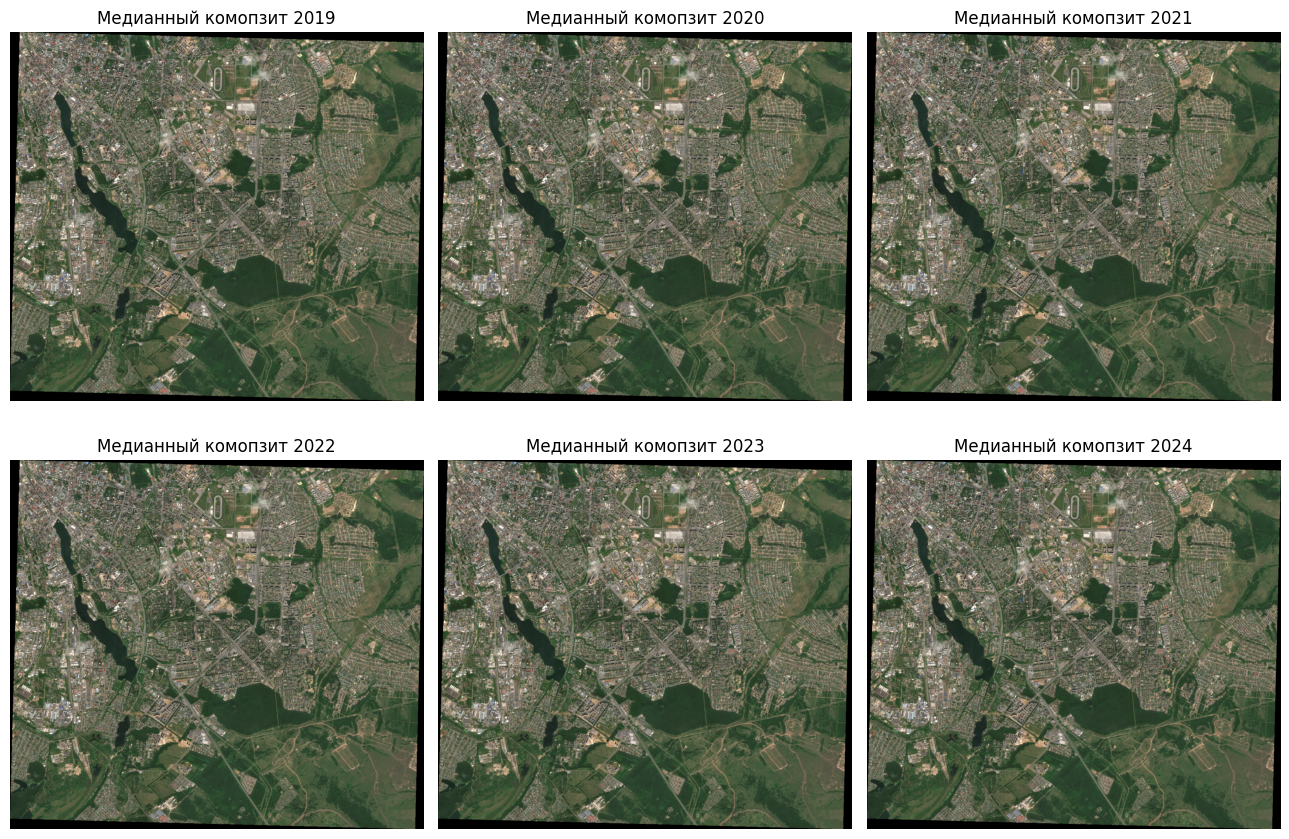

In [111]:
def open_sentinel(filename):
  with rasterio.open(filename) as src:
      rgb = src.read([3, 2, 1])
  rgb = np.clip(np.nan_to_num(np.transpose(rgb, (1, 2, 0))) / 0.3, 0, 1) ** (1 / 1.4)
  return rgb

plt.figure(figsize=(13, 9))

plt.subplot(2,3,1)
plt.imshow(open_sentinel('sentinel2_summer_2019.tif'))
plt.title('Медианный комопзит 2019')
plt.axis('off')

plt.subplot(2,3,2)
plt.imshow(open_sentinel('sentinel2_summer_2020.tif'))
plt.title('Медианный комопзит 2020')
plt.axis('off')

plt.subplot(2,3,3)
plt.imshow(open_sentinel('sentinel2_summer_2021.tif'))
plt.title('Медианный комопзит 2021')
plt.axis('off')

plt.subplot(2,3,4)
plt.imshow(open_sentinel('sentinel2_summer_2022.tif'))
plt.title('Медианный комопзит 2022')
plt.axis('off')

plt.subplot(2,3,5)
plt.imshow(open_sentinel('sentinel2_summer_2023.tif'))
plt.title('Медианный комопзит 2023')
plt.axis('off')

plt.subplot(2,3,6)
plt.imshow(open_sentinel('sentinel2_summer_2024.tif'))
plt.title('Медианный комопзит 2024')
plt.axis('off')

plt.tight_layout()
plt.show()

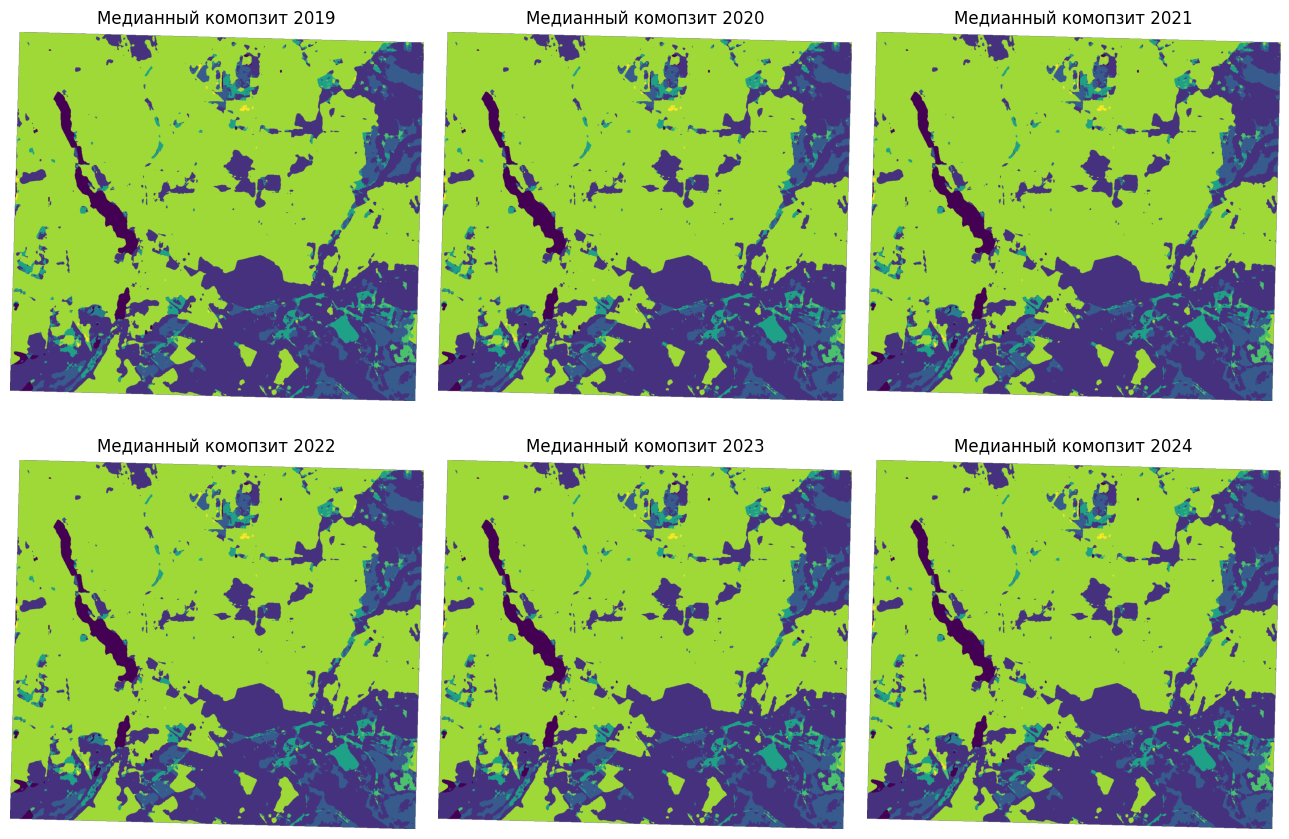

In [120]:
plt.figure(figsize=(13,9))

plt.subplot(2,3,1)
plt.imshow(rasterio.open('DYNAMICWORLD_summer_2019.tif').read(1))
plt.title('Медианный комопзит 2019')
plt.axis('off')

plt.subplot(2,3,2)
plt.imshow(rasterio.open('DYNAMICWORLD_summer_2020.tif').read(1))
plt.title('Медианный комопзит 2020')
plt.axis('off')

plt.subplot(2,3,3)
plt.imshow(rasterio.open('DYNAMICWORLD_summer_2021.tif').read(1))
plt.title('Медианный комопзит 2021')
plt.axis('off')

plt.subplot(2,3,4)
plt.imshow(rasterio.open('DYNAMICWORLD_summer_2022.tif').read(1))
plt.title('Медианный комопзит 2022')
plt.axis('off')

plt.subplot(2,3,5)
plt.imshow(rasterio.open('DYNAMICWORLD_summer_2023.tif').read(1))
plt.title('Медианный комопзит 2023')
plt.axis('off')

plt.subplot(2,3,6)
plt.imshow(rasterio.open('DYNAMICWORLD_summer_2024.tif').read(1))
plt.title('Медианный комопзит 2024')
plt.axis('off')

plt.tight_layout()
plt.show()

### **4.2. Рассчитать все 8 индексов для каждого года (2019-2024)**


> **Примечание.** В качестве примера рассчета индексов можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/4qBeIg





**Спектральные индексы** — это математические комбинации значений отражения в разных спектральных каналах, позволяющие выделить определенные типы объектов.








#### **Таблица 1. Основные спектральные индексы для анализа земного покрова**




| **Индекс** | **Формула** | **Назначение** | **Каналы Sentinel-2** |
|------------|-------------|----------------|------------------------|
| **NDVI** (Normalized Difference Vegetation Index) | (NIR - RED) / (NIR + RED) | Оценка состояния растительности | (B8 - B4) / (B8 + B4) |
| **NDWI** (Normalized Difference Water Index) | (GREEN - NIR) / (GREEN + NIR) | Выделение водных объектов | (B3 - B8) / (B3 + B8) |
| **NDBI** (Normalized Difference Built-up Index) | (SWIR - NIR) / (SWIR + NIR) | Выделение застроенных территорий | (B11 - B8) / (B11 + B8) |
| **SAVI** (Soil Adjusted Vegetation Index) | ((NIR - RED) / (NIR + RED + L)) * (1 + L), L=0.5 | Растительность с учетом почвы | ((B8 - B4) / (B8 + B4 + 0.5)) * 1.5 |
| **EVI** (Enhanced Vegetation Index) | 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1)) | Улучшенный вегетационный индекс | 2.5 * ((B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)) |
| **MNDWI** (Modified NDWI) | (GREEN - SWIR) / (GREEN + SWIR) | Модифицированный водный индекс | (B3 - B11) / (B3 + B11) |
| **BSI** (Bare Soil Index) | ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE)) | Открытая почва | ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)) |
| **NDSI** (Normalized Difference Snow Index) | (GREEN - SWIR) / (GREEN + SWIR) | Снежный покров | (B3 - B11) / (B3 + B11) |

NDSI и MNDWI вычисляются по одной формуле, поэтому высокие значения дают и снег, и вода. Снег отличается от воды высоким отражением в ближнем ИК-канале (B8 > 0.11), а вода ИК-излучение поглощает.


#### **Таблица 2. Интерпретация значений NDVI**



| **Диапазон NDVI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| < 0.0 | Вода | Водные поверхности, снег |
| 0.0 - 0.1 | Открытая почва | Песок, камни, бетон |
| 0.1 - 0.2 | Разреженная растительность | Степи, пустыни |
| 0.2 - 0.4 | Умеренная растительность | Кустарники, луга |
| 0.4 - 0.6 | Плотная растительность | Лиственные леса |
| > 0.6 | Очень плотная растительность | Тропические леса, хвойные леса |

#### **Таблица 3. Интерпретация значений NDWI**



| **Диапазон NDWI** | **Тип объекта** | **Описание** |
|-------------------|-----------------|--------------|
| > 0.3 | Водные объекты | Реки, озера, пруды |
| 0.0 - 0.3 | Влажная почва/растительность | Болота, заливные луга |
| -0.3 - 0.0 | Сухая растительность | Обычная растительность |
| < -0.3 | Застройка/почва | Городская застройка, открытая почва |

#### **Таблица 4. Интерпретация значений NDBI**



| **Диапазон NDBI** | **Тип территории** | **Характеристика** |
|-------------------|-------------------|---------------------|
| > 0.0 | Застроенные территории | Города, промзоны |
| -0.1 - 0.0 | Смешанные территории | Пригороды, села |
| < -0.1 | Природные территории | Леса, поля, водоемы |

#### **Таблица 5. Интерпретация значений SAVI**



| **Диапазон SAVI** | **Тип покрова** | **Описание** |
|-------------------|-----------------|---------------|
| < 0.1 | Открытая почва/вода | Водные объекты, голая почва |
| 0.1 - 0.2 | Очень разреженная растительность | Пустыни, каменистые участки |
| 0.2 - 0.4 | Разреженная растительность | Степи, саванны |
| 0.4 - 0.6 | Умеренная растительность | Сельхозугодья, луга |
| > 0.6 | Плотная растительность | Леса, густые кустарники |

#### **Таблица 6. Интерпретация значений EVI**



| **Диапазон EVI** | **Состояние растительности** | **Характеристика** |
|------------------|------------------------------|---------------------|
| < 0.0 | Нет растительности | Вода, снег, облака |
| 0.0 - 0.2 | Минимальная растительность | Голая почва, урбанизированные территории |
| 0.2 - 0.3 | Низкая биомасса | Травянистая растительность |
| 0.3 - 0.5 | Средняя биомасса | Кустарники, молодые посевы |
| 0.5 - 0.8 | Высокая биомасса | Зрелые леса, интенсивное сельское хозяйство |
| > 0.8 | Очень высокая биомасса | Тропические леса |

#### **Таблица 7. Интерпретация значений MNDWI**



| **Диапазон MNDWI** | **Тип объекта** | **Характеристика** |
|--------------------|-----------------|---------------------|
| > 0.5 | Глубокая вода | Озера, моря, водохранилища |
| 0.2 - 0.5 | Мелкая вода | Реки, каналы, мелководья |
| 0.0 - 0.2 | Влажные территории | Болота, рисовые поля |
| < 0.0 | Суша | Растительность, почва, застройка |

#### **Таблица 8. Интерпретация значений BSI**



| **Диапазон BSI** | **Тип поверхности** | **Описание** |
|-------------------|-------------------|---------------|
| > 0.1 | Открытая почва | Пашни, карьеры, пустыни |
| 0.0 - 0.1 | Частично покрытая почва | Разреженная растительность |
| -0.1 - 0.0 | Смешанный покров | Переходные зоны |
| < -0.1 | Растительность/вода | Леса, водоемы, плотная растительность |

#### **Таблица 9. Интерпретация значений NDSI**



| **Диапазон NDSI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| > 0.4 | Снежный покров | Чистый снег, ледники |
| 0.2 - 0.4 | Частичный снежный покров | Смешанный снег с растительностью |
| 0.0 - 0.2 | Возможный снег/лед | Тающий снег, иней, облака |
| -0.2 - 0.0 | Переходная зона | Влажная почва, туман |
| < -0.2 | Бесснежные территории | Растительность, почва, вода |

In [ ]:
# Ваш код

### **4.3. Визуализировать каждый индекс для 2024 года с соответствующей цветовой шкалой**



In [ ]:
# Ваш код

### **4.4. Сохранить все рассчитанные индексы в отдельные GeoTIFF файлы с сохранением геопривязки (сохранить в соответствующие папки по годам)**



In [ ]:
# Ваш код

## **5. Сегментация и классификация**

**Сегментация** — процесс разделения изображения на однородные регионы (сегменты) на основе заданных критериев .


### **5.1. Многопороговая сегментация с использованием спектральных индексов**



**Задание:** Реализовать классификацию земного покрова путем замены значений пикселей в растрах индексов на метки классов согласно пороговым правилам.

**Пояснение:** По сути необходимо преобразовать непрерывные значения индексов в дискретные классы (метки) на основе пороговых значений из Таблиц 2-9. Каждому пикселю присваивается числовая метка класса (0-7) в зависимости от значений спектральных индексов.






**Алгоритм многопороговой сегментации:**
1. Создать пустой растр для меток классов (заполнить значением -1 или 255 для "неклассифицировано")
2. Последовательно применить правила классификации
3. Каждое правило проверяется только для еще не классифицированных пикселей
4. Присвоить соответствующую метку класса пикселям, удовлетворяющим условию

**Иерархия правил классификации (применять строго последовательно):**
1. **Снег/лед (метка=1)**: (NDSI > 0.4) И (B8 > 0.11)
2. **Вода (метка=0)**: ((NDWI > 0.3) ИЛИ (MNDWI > 0.2)) И (еще не классифицировано)
3. **Застройка (метка=2)**: (NDBI > 0.0) И (NDVI < 0.2) И (еще не классифицировано)
4. **Густая растительность (метка=3)**: ((NDVI > 0.6) ИЛИ (EVI > 0.5)) И (еще не классифицировано)
5. **Умеренная растительность (метка=4)**: (0.3 ≤ NDVI ≤ 0.6) И (еще не классифицировано)
6. **Разреженная растительность (метка=5)**: (0.1 ≤ NDVI < 0.3) И (еще не классифицировано)
7. **Открытая почва (метка=6)**: (BSI > 0.0) И (NDVI < 0.1) И (еще не классифицировано)
8. **Прочее (метка=7)**: все оставшиеся неклассифицированные пиксели

**Обратите внимание:** открытая почва и пашня, как и застройка, дают NDBI > 0, поэтому правило 3 относит часть открытой почвы к застройке. Учитывайте это при интерпретации результатов и сравнении с Dynamic World.


**(МОЖЕТЕ СФОРМУЛИРОВАТЬ СВОИ ПРАВИЛА, ОСНОВЫВАЯСЬ НА ТАБЛИЦАХ, ПРИВЕДЕННЫХ ВЫШЕ!)**

In [ ]:
# Ваш код


### **5.2. Подсчет количества пикселей каждого класса**



**Задание:** После замены значений индексов на метки классов, подсчитать количество пикселей для каждой метки класса.

**Пояснение:** Используйте функции numpy.unique() или аналогичные для подсчета количества пикселей с каждой меткой. Это позволит получить статистику распределения классов на изображении.

**Что нужно получить:**
- Массив уникальных меток классов (0-7)
- Количество пикселей для каждой метки
- Процентное соотношение классов от общего числа пикселей

In [ ]:
# Ваш код

### **5.3. Применение сегментации ко всем временным срезам**




**Задание:** Применить разработанный алгоритм сегментации ко всем медианным композитам (2019-2024).

**Пояснение:** Использовать одинаковые пороговые значения для всех лет для обеспечения сопоставимости результатов при анализе динамики. Сохранить результаты сегментации как растры с метками классов.

**Выходные данные:**
- 6 растров с метками классов (по одному на каждый год)
- Таблица с количеством пикселей каждого класса для каждого года
- Формат сохранения: GeoTIFF с сохранением геопривязки

In [ ]:
# Ваш код

### **5.4. Визуализация результатов сегментации**






**Задание:** Создать тематические карты классификации с легендой.

**Пояснение:** Назначить каждой метке класса соответствующий цвет для визуализации. Использовать стандартную цветовую схему для классов земного покрова.

**Цветовая схема для визуализации:**
- 0 - Вода: синий (#419bdf)
- 1 - Снег/лед: белый (#ffffff)  
- 2 - Застройка: красный (#c4281b)
- 3 - Густая растительность: темно-зеленый (#397d49)
- 4 - Умеренная растительность: зеленый (#88b053)
- 5 - Разреженная растительность: светло-зеленый (#c6e48b)
- 6 - Открытая почва: коричневый (#a59b8f)
- 7 - Прочее: серый (#808080)

In [ ]:
# Ваш код

## **6. Анализ динамики изменений на сегментированных растрах**

### **6.1. Рассчитать площади всех классов для каждого года**



**Формула перевода пикселей в площадь:**
```
Площадь (га) = Количество_пикселей × (Разрешение_м)² / 10000
Площадь (км²) = Количество_пикселей × (Разрешение_м)² / 1000000
```
Для Sentinel-2: разрешение = 10 м, следовательно:
- 1 пиксель = 100 м² = 0.01 га
- 100 пикселей = 1 га
- 10000 пикселей = 1 км²

Формула верна для растров в метрической проекции (UTM), где размер пикселя задан в метрах; размер пикселя берите из растра (`src.res`).

In [ ]:
# Ваш код

### **6.2. Построить графики динамики изменений для каждого класса**



In [ ]:
# Ваш код

### **6.3. Рассчитать все статистические показатели**



**Обязательные метрики для каждого класса:**

1. **Абсолютные показатели:**
   - Площадь в га и км² для каждого года
   - Количество пикселей
   - Процент от общей площади ROI

2. **Показатели изменений:**
   - Абсолютное изменение площади (га): ΔS = S₂₀₂₄ - S₂₀₁₉
   - Относительное изменение (%): (S₂₀₂₄ - S₂₀₁₉) / S₂₀₁₉ × 100%
   - Среднегодовой прирост (га/год): ΔS / количество_лет (2024 - 2019 = 5)
   - Среднегодовой темп роста (%/год): ((S₂₀₂₄/S₂₀₁₉)^(1/5) - 1) × 100%

3. **Статистика временного ряда:**
   - Коэффициент вариации: CV = σ/μ × 100% (вспомните материал прошлого семестра, а именно работу в numpy)
   - Стандартное отклонение площадей
   - Наклон линейного тренда площади (га/год) и коэффициент детерминации R² (`np.polyfit`)

In [ ]:
# Ваш код

### **6.4. Определить какие классы показали наибольшие изменения**



**Критерии определения значимых изменений:**
- Изменение площади > 10% от начального значения
- Абсолютное изменение > 10 га
- Изменение направленное: R² линейного тренда ≥ 0.5 (иначе это межгодовые колебания)
- Ранжировать классы по величине относительных изменений

In [ ]:
# Ваш код

### **6.5. Создать сводную таблицу результатов**



| Класс | S_2019 (га) | S_2024 (га) | ΔS (га) | Δ% | Темп (%/год) | Тренд | CV (%) | R² |
|-------|-------------|-------------|---------|-----|--------------|-------|-----|-----|
| Вода | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| Растительность | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| ... | ... | ... | ... | ... | ... | ... | ... | ... |

In [ ]:
# Ваш код

### **6.6. Карта изменений и матрица переходов**

**Задание:** Постройте карту пикселей, сменивших класс с 2019 по 2024 год, и матрицу переходов — площадь (га), перешедшую из каждого класса в каждый. Определите, где сосредоточены основные изменения и какие переходы преобладают.

In [ ]:
# Ваш код

## **7. Сравнение с картами Dynamic World**

### **7.1. Рассчитать площади всех классов для каждого года по картам классификации**



In [ ]:
# Ваш код

### **7.2. Построить графики динамики изменений для каждого класса по картам классификации**



In [ ]:
# Ваш код

### **7.3. Рассчитать все статистические показатели по картам классификации**



In [ ]:
# Ваш код

### **7.4. Определить какие классы показали наибольшие изменения по картам классификации**



In [ ]:
# Ваш код

### **7.5. Создать сводную таблицу результатов по картам классификации**



In [ ]:
# Ваш код

## **8. Сравнение результатов полученных по результатам сегментации и картам классификаций**

**Задание:** Сведите классы обоих методов к укрупнённым классам по таблице 10. Сравните площади укрупнённых классов по годам, рассчитайте долю совпадающих пикселей для каждого года и матрицу совпадений для 2024 года.

#### **Таблица 10. Соответствие классов сегментации и Dynamic World**

| **Укрупнённый класс** | **Метки сегментации** | **Классы Dynamic World** |
|---|---|---|
| Вода | 0 | 0 — Вода |
| Снег/лед | 1 | 8 — Снег и лед |
| Застройка | 2 | 6 — Застройка |
| Растительность | 3, 4, 5 | 1 — Деревья, 2 — Трава, 3 — Затопл. растительность, 4 — Культуры, 5 — Кустарники |
| Открытая почва | 6 | 7 — Голая земля |
| Прочее | 7 | — |

In [ ]:
# Ваш код

## **9. Выводы**

В выводах обязательно отразить:
1. **Количественная оценка динамики** (с конкретными цифрами для каждого класса)
2. **Выявленные тренды** (растущие, убывающие, стабильные классы)
3. **Скорость изменений** (га/год и %/год для ключевых классов)
4. **Пространственные закономерности** (где происходят основные изменения)
5. **Согласованность методов** (доля совпадающих пикселей по укрупнённым классам в % и основные причины расхождений)



```
# ВАШИ ВЫВОДЫ
```

